https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database

https://colab.research.google.com/drive/1Mh_8MeinXMFFk9aqIBZQwTOZzJ4g-eXg#scrollTo=9aG51VjcDOvJ

Dataset "COVID-19 Radiography Database" trên Kaggle do nhóm nghiên cứu từ Qatar University, University of Dhaka cùng các cộng tác viên y tế quốc tế phát triển. Đây là một trong những bộ dữ liệu hình ảnh y tế phổ biến và đạt giải thưởng lớn trong cộng đồng Kaggle nhằm hỗ trợ chẩn đoán và sàng lọc COVID-19 bằng Trí tuệ nhân tạo (AI) và Deep Learning.

Bộ dữ liệu bao gồm các ảnh chụp X-quang ngực (Chest X-ray - CXR) cùng với các mặt nạ phân vùng phổi (lung segmentation masks) tương ứng. Các phiên bản cập nhật lớn bao gồm 4 nhóm phân loại chính:

COVID-19 Positive Cases: Các ca nhiễm COVID-19 được tổng hợp từ nhiều nguồn công khai, kho lưu trữ y tế (như SIRM, BIMCV, các bài báo khoa học và kho mã nguồn mở).

Normal: Các ca phổi bình thường (không có dấu hiệu bệnh lý).

Viral Pneumonia: Các ca viêm phổi do virus thông thường.

Lung Opacity: Các ca có độ mờ ở phổi (Non-COVID lung infection - tổn thương phổi không do COVID).

Định dạng tệp: Toàn bộ ảnh có định dạng PNG với kích thước chuẩn 299x299 pixels, thuận tiện cho việc đưa vào các mô hình mạng neural tích chập (CNN) hoặc các mô hình Vision Transformers (ViT).

3. Mục đích và Ứng dụng trong AI / Machine Learning
Bộ dữ liệu này được thiết kế chủ yếu cho các mục đích nghiên cứu học thuật và phi thương mại, rất thích hợp để thực hiện các bài toán:

Image Classification (Phân loại hình ảnh): Xây dựng các mô hình Deep Learning (như ResNet, DenseNet, EfficientNet, MobileNet) để tự động phân biệt ảnh X-quang thành các nhãn: COVID, Normal, Viral Pneumonia, Lung Opacity.

Segmentation (Phân đoạn hình ảnh): Tận dụng các lung masks đi kèm để huấn luyện các mô hình phân đoạn (như U-Net) nhằm khoanh vùng chính xác khu vực phổi bị ảnh hưởng.

Transfer Learning & Fine-tuning: Thích hợp cho việc thử nghiệm các kỹ thuật tăng cường dữ liệu (Data Augmentation), học chuyển giao (Transfer Learning) và đánh giá độ chính xác của mô hình y tế.

# import Tools

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

# Deep Learning Tools
from keras import layers, models
import keras
from keras.models import Sequential, Model
from keras.layers import Conv2D, MaxPool2D
from keras.layers import Activation, Dropout, BatchNormalization, Flatten, Dense
from keras.optimizers import Adam
from keras.utils import to_categorical


# Machine Learning Tools
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

import matplotlib.image as mpimg: Module chuyên dụng của Matplotlib dùng để đọc và tải file ảnh (dưới dạng mảng NumPy).



from tensorflow.keras import layers, models: Import các thành phần cơ bản để xây dựng mô hình mạng neural từ TensorFlow Keras.

import keras: Nhập thư viện Keras (API cấp cao để xây dựng mạng neural).

from keras.models import Sequential, Model:

Sequential: Mô hình tuần tự (các lớp xếp chồng lên nhau theo thứ tự tuyến tính từ trên xuống).

Model: Mô hình Functional API (cho phép xây dựng các kiến trúc phức tạp hơn như mạng có nhiều đầu vào/đầu ra hoặc nhánh phụ).

from keras.layers import Conv2D, MaxPool2D: Các lớp đặc trưng cho mạng CNN (Convolutional Neural Network) xử lý ảnh:

Conv2D: Lớp tích chập 2D dùng để trích xuất các đặc trưng hình ảnh (cạnh, góc, texture...).

MaxPool2D: Lớp gộp cực đại (Max Pooling) giúp giảm kích thước không gian của ảnh, giảm số lượng tham số và chống overfitting.

from keras.layers import Activation, Dropout, BatchNormalization, Flatten, Dense: Các lớp bổ trợ trong mạng:

Activation: Hàm kích hoạt (như ReLU, Softmax) quyết định đầu ra của neuron.

Dropout: Kỹ thuật ngắt kết nối ngẫu nhiên một số neuron trong quá trình train để chống học vẹt (overfitting).

BatchNormalization: Chuẩn hóa đầu ra của các lớp giúp mô hình học nhanh hơn và ổn định hơn.

Flatten: Chuyển đổi dữ liệu từ dạng ma trận 2D/3D (sau lớp CNN) thành vector 1D để đưa vào lớp Dense.

Dense: Lớp kết nối đầy đủ (Fully Connected Layer) dùng để đưa ra dự đoán cuối cùng.

from keras.optimizers import Adam: Thuật toán tối ưu hóa Adam (kết hợp giữa Momentum và RMSprop) dùng để cập nhật trọng số của mạng trong quá trình huấn luyện.

from keras.utils import to_categorical: Hàm chuyển đổi nhãn dạng số nguyên thành dạng One-Hot Encoding (ví dụ: nhãn 0, 1, 2 thành [1,0,0], [0,1,0], [0,0,1]).

# Data Loading

In [3]:
import kagglehub
path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.


In [4]:
import os
import pandas as pd
import kagglehub

# Kiểm tra nếu chưa có biến 'path', tự động tải lại bằng kagglehub để tránh lỗi
if 'path' not in globals():
    print("🔄 Không tìm thấy biến 'path'. Đang tải lại thông tin đường dẫn từ kagglehub...")
    path = kagglehub.dataset_download("tawsifurrahman/covid19-radiography-database")

# Xác định đường dẫn thư mục dataset thực tế từ kagglehub
dataset_dir = os.path.join(path, 'COVID-19_Radiography_Dataset')

image_paths = []
labels = []

# Các lớp bệnh cần quét trong dataset
classes = ['COVID', 'Normal', 'Lung_Opacity', 'Viral Pneumonia']

if os.path.exists(dataset_dir):
    for class_name in classes:
        class_dir = os.path.join(dataset_dir, class_name, 'images')
        if not os.path.exists(class_dir):
            class_dir = os.path.join(dataset_dir, class_name)

        if os.path.exists(class_dir):
            for root, _, files in os.walk(class_dir):
                for file in files:
                    if file.lower().endswith('.png'):
                        image_paths.append(os.path.join(root, file))
                        labels.append(class_name)

# Tạo lại DataFrame quản lý thông tin ảnh
df_dataset = pd.DataFrame({
    'image_path': image_paths,
    'label': labels
})

print(f"✅ Đã tạo lại df_dataset thành công với: {len(df_dataset)} ảnh!")
display(df_dataset.head())

✅ Đã tạo lại df_dataset thành công với: 21165 ảnh!


,image_path,label
0,/kaggle/input/covid19-radiography-database/COV...,COVID
1,/kaggle/input/covid19-radiography-database/COV...,COVID
2,/kaggle/input/covid19-radiography-database/COV...,COVID
3,/kaggle/input/covid19-radiography-database/COV...,COVID
4,/kaggle/input/covid19-radiography-database/COV...,COVID


In [7]:
df_dataset['label'].value_counts()

,count
label,
Normal,10192
Lung_Opacity,6012
COVID,3616
Viral Pneumonia,1345


COVID (Covid-19)

Normal (Ảnh phổi bình thường)

Lung_Opacity (Tổn thương phổi mờ/khác)

Viral Pneumonia (Viêm phổi do virus)

In [4]:
# import cv2
# from tqdm import tqdm
# import numpy as np
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import LabelEncoder
# from keras.utils import to_categorical

# resize = 150
# cat = {
#     'Viral Pneumonia': 'Pneumonia',
#     'Normal': 'Normal',
#     'COVID': 'Covid-19',
#     'Lung_Opacity': 'Lung_Opacity'
# }

# # Lọc bỏ các dòng không hợp lệ
# df_valid = df_dataset[df_dataset['label'].isin(cat.keys())].copy()
# df_valid['mapped_label'] = df_valid['label'].map(cat)

# # 1. Chia tập Train+Val và Test ngay trên DataFrame (trước khi đọc ảnh)
# train_val_df, test_df = train_test_split(
#     df_valid, test_size=0.20, stratify=df_valid['mapped_label'], random_state=42
# )

# # 2. Chia tiếp train_val thành train và val
# train_df, val_df = train_test_split(
#     train_val_df, test_size=0.20, stratify=train_val_df['mapped_label'], random_state=42
# )

# print(f"📊 Số lượng phân chia:")
# print(f" - Train: {len(train_df)} ảnh")
# print(f" - Validation: {len(val_df)} ảnh")
# print(f" - Test: {len(test_df)} ảnh")

📊 Số lượng phân chia:
 - Train: 13545 ảnh
 - Validation: 3387 ảnh
 - Test: 4233 ảnh


In [5]:
# def load_images_from_df(df, resize=150):
#     images = np.zeros((len(df), resize, resize, 3), dtype=np.float32)
#     targets = []

#     for i, (_, row) in enumerate(tqdm(df.iterrows(), total=len(df))):
#         image = cv2.imread(row['image_path'])
#         if image is not None:
#             image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#             image = cv2.resize(image, (resize, resize)) / 255.0
#             images[i] = image
#             targets.append(row['mapped_label'])

#     return images, np.array(targets)

# print("🔄 Đang load tập Train...")
# raw_trainX, raw_trainY = load_images_from_df(train_df, resize)

# print("🔄 Đang load tập Validation...")
# raw_valX, raw_valY = load_images_from_df(val_df, resize)

# print("🔄 Đang load tập Test...")
# raw_testX, raw_testY = load_images_from_df(test_df, resize)

🔄 Đang load tập Train...


100%|██████████| 13545/13545 [01:30<00:00, 150.46it/s]


🔄 Đang load tập Validation...


100%|██████████| 3387/3387 [00:21<00:00, 158.95it/s]


🔄 Đang load tập Test...


100%|██████████| 4233/4233 [00:25<00:00, 165.88it/s]


# label Encoding and to one hot encoding

[[0., 1., 0.], # 'Normal' -> [0, 1, 0]

[0., 0., 1.], # 'Pneumonia' -> [0, 0, 1]

[1., 0., 0.]] # 'Covid-19' -> [1, 0, 0]

In [ ]:
# le = LabelEncoder()
# # Fit trên toàn bộ nhãn để đảm bảo khớp các lớp
# le.fit(list(cat.values()))

# trainY_encoded = le.transform(raw_trainY)
# valY_encoded = le.transform(raw_valY)
# testY_encoded = le.transform(raw_testY)

# trainY = to_categorical(trainY_encoded, num_classes=4)
# valY = to_categorical(valY_encoded, num_classes=4)
# testY = to_categorical(testY_encoded, num_classes=4)

# trainX = raw_trainX
# valX = raw_valX
# testX = raw_testX

# print("Training data shape:", trainX.shape)
# print("Validation data shape:", valX.shape)
# print("Testing data shape:", testX.shape)
# print("Training labels shape:", trainY.shape)
# print("Validation labels shape:", valY.shape)
# print("Testing labels shape:", testY.shape)

# Splitting Dataset

In [7]:
# le = LabelEncoder()
# # Fit trên toàn bộ nhãn để đảm bảo khớp các lớp
# le.fit(list(cat.values()))

# trainY_encoded = le.transform(raw_trainY)
# valY_encoded = le.transform(raw_valY)
# testY_encoded = le.transform(raw_testY)

# trainY = to_categorical(trainY_encoded, num_classes=4)
# valY = to_categorical(valY_encoded, num_classes=4)
# testY = to_categorical(testY_encoded, num_classes=4)

# trainX = raw_trainX
# valX = raw_valX
# testX = raw_testX

# print("Training data shape:", trainX.shape)
# print("Validation data shape:", valX.shape)
# print("Testing data shape:", testX.shape)
# print("Training labels shape:", trainY.shape)
# print("Validation labels shape:", valY.shape)
# print("Testing labels shape:", testY.shape)

Training data shape: (13545, 150, 150, 3)
Validation data shape: (3387, 150, 150, 3)
Testing data shape: (4233, 150, 150, 3)
Training labels shape: (13545, 4)
Validation labels shape: (3387, 4)
Testing labels shape: (4233, 4)


# CNN Model Training

In [ ]:
# import keras
# from keras.models import Sequential
# from keras.layers import Conv2D, MaxPool2D, Flatten, Dense, Dropout

# s = 150  # Size

# model = Sequential()

# model.add(Conv2D(filters=32, kernel_size=(3, 3), activation="relu", input_shape=(s, s, 3), kernel_initializer='he_normal'))
# model.add(MaxPool2D(pool_size=(2, 2)))
# model.add(Conv2D(filters=64, kernel_size=(3, 3), activation="relu"))
# model.add(MaxPool2D(pool_size=(2, 2)))
# model.add(Conv2D(filters=128, kernel_size=(3, 3), activation="relu"))
# model.add(MaxPool2D(pool_size=(2, 2), strides=(1, 1)))
# model.add(Dropout(0.25))

# model.add(Flatten())
# model.add(Dense(64, activation="relu"))
# model.add(Dropout(0.2))
# model.add(Dense(4, activation="softmax"))

# model.compile(optimizer=keras.optimizers.Adam(),
#               loss=keras.losses.categorical_crossentropy,
#               metrics=['accuracy'])

# epochs = 25
# history = model.fit(trainX, trainY, epochs=epochs, batch_size=40, verbose=1, validation_data=(valX, valY))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# thieu ram

In [5]:
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPool2D, Flatten, Dense, Dropout

# 1. Cấu hình thông số
IMG_SIZE = 150
BATCH_SIZE = 32  # Đọc từng batch nhỏ, cực kỳ tiết kiệm RAM

print("📂 Đang tải dữ liệu trực tiếp từ ổ cứng theo chuẩn Keras (An toàn tuyệt đối cho RAM)...")

# 2. Tạo tập Train (80% của 80% hoặc trực tiếp từ dataset_dir)
train_dataset = image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# 3. Tạo tập Validation (20%)
val_dataset = image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Tự động chuẩn hóa ảnh từ [0, 255] về [0, 1] ngay trong mạng
normalization_layer = tf.keras.layers.Rescaling(1./255)

# 4. Xây dựng đúng nguyên văn mô hình của bạn
s = 150  # Size
model = Sequential()

model.add(tf.keras.Input(shape=(s, s, 3)))
model.add(normalization_layer)

model.add(Conv2D(filters=32, kernel_size=(3, 3), activation="relu", kernel_initializer='he_normal'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation="relu"))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation="relu"))
model.add(MaxPool2D(pool_size=(2, 2), strides=(1, 1)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(64, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(4, activation="softmax"))

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.categorical_crossentropy,
    metrics=['accuracy']
)

model.summary()

# 5. Huấn luyện trực tiếp không sợ tràn RAM
epochs = 25
print(f"\n🚀 Bắt đầu huấn luyện mô hình với toàn bộ dữ liệu...")

history = model.fit(
    train_dataset,
    epochs=epochs,
    validation_data=val_dataset,
    verbose=1
)

📂 Đang tải dữ liệu trực tiếp từ ổ cứng theo chuẩn Keras (An toàn tuyệt đối cho RAM)...
Found 42330 files belonging to 4 classes.
Using 33864 files for training.
Found 42330 files belonging to 4 classes.
Using 8466 files for validation.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 33, 33, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 33, 33, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 139392)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     8,921,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,014,660 (34.39 MB)

 Trainable params: 9,014,660 (34.39 MB)

 Non-trainable params: 0 (0.00 B)


🚀 Bắt đầu huấn luyện mô hình với toàn bộ dữ liệu...
Epoch 1/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 126s 109ms/step - accuracy: 0.6125 - loss: 0.9318 - val_accuracy: 0.7159 - val_loss: 0.7119
Epoch 2/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 60s 57ms/step - accuracy: 0.7161 - loss: 0.6970 - val_accuracy: 0.7470 - val_loss: 0.6331
Epoch 3/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 79s 54ms/step - accuracy: 0.7493 - loss: 0.6176 - val_accuracy: 0.7731 - val_loss: 0.5664
Epoch 4/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 57s 54ms/step - accuracy: 0.7739 - loss: 0.5702 - val_accuracy: 0.7718 - val_loss: 0.5681
Epoch 5/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 93s 64ms/step - accuracy: 0.7954 - loss: 0.5164 - val_accuracy: 0.7850 - val_loss: 0.5407
Epoch 6/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 67s 63ms/step - accuracy: 0.8057 - loss: 0.4821 - val_accuracy: 0.7817 - val_loss: 0.5675
Epoch 7/25
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 66s 62ms/step - accuracy: 0.8243 - loss: 0.4416 - val_accuracy: 0.7869 - val_loss: 0.5596
Epoch 8/25
1059/1059 

Phần 1: Khai báo thư viện & Đọc dữ liệu dạng Batch
from tensorflow.keras.utils import image_dataset_from_directory: Hàm chuẩn của Keras giúp đọc ảnh trực tiếp từ thư mục trên ổ cứng mà không cần load tất cả vào RAM cùng một lúc (giúp tránh hoàn toàn lỗi tràn RAM).

train_dataset = image_dataset_from_directory(...): Tự động quét các thư mục con bên trong dataset_dir (COVID, Normal,...) làm nhãn, cắt 80% dữ liệu làm tập huấn luyện, resize ảnh về (150, 150), gom thành từng nhóm batch_size=32, và mã hóa nhãn dạng categorical (One-Hot).

val_dataset = ...: Lấy 20% dữ liệu còn lại làm tập kiểm định (validation) với cùng cấu hình trên.

normalization_layer = tf.keras.layers.Rescaling(1./255): Chia giá trị mỗi điểm ảnh cho 255 để đưa về khoảng [0, 1], giúp mô hình học tập ổn định và nhanh hội tụ hơn.

Phần 2: Xây dựng kiến trúc mô hình CNN cơ bản
Mô hình này là một mạng Convolutional Neural Network (CNN) cổ điển nhưng rất hiệu quả cho bài toán phân loại ảnh X-quang:

Sequential(): Khởi tạo mô hình dạng chuỗi (các tầng xếp chồng tuần tự từ trên xuống).

Tầng 1 - Trích xuất đặc trưng cơ bản (Conv2D + MaxPool2D):

Conv2D(filters=32, kernel_size=(3, 3), activation="relu"): Dùng 32 bộ lọc (kernel) kích thước 3x3 quét qua ảnh để tìm các đặc trưng nông như đường nét, góc cạnh, độ sáng tối. Hàm kích hoạt relu giúp loại bỏ các giá trị âm.

MaxPool2D(pool_size=(2, 2)): Giảm kích thước ảnh xuống một nửa (pooling) bằng cách lấy giá trị lớn nhất trong vùng 2x2, giúp giảm số lượng tham số và chống overfitting.

Tầng 2 & 3 - Trích xuất đặc trưng sâu hơn:

Tiếp tục dùng Conv2D với số bộ lọc tăng dần (64 rồi 128) để bắt các chi tiết phức tạp hơn của tổn thương phổi.

Dropout(0.25): Tắt ngẫu nhiên 25% các nơ-ron trong quá trình huấn luyện để ép mô hình không bị học thuộc lòng (overfitting).

Phần phân loại (Dense / Fully Connected):

Flatten(): Duỗi mảng đa chiều hình ảnh sau khi qua các tầng Conv thành dạng vector 1 chiều để đưa vào mạng Neural thông thường (ANN).

Dense(64, activation="relu"): Tầng ẩn gồm 64 nơ-ron giúp tổng hợp các đặc trưng đã học để đưa ra phán đoán.

Dropout(0.2): Tiếp tục tắt ngẫu nhiên 20% nơ-ron để tăng độ tổng quát hóa.

Dense(4, activation="softmax"): Tầng đầu ra có 4 nơ-ron tương ứng với 4 lớp bệnh (COVID, Normal, Lung Opacity, Viral Pneumonia). Hàm softmax trả về xác suất tổng bằng 1 cho cả 4 lớp.

Phần 3: Biên soạn & Huấn luyện (Compile & Fit)
model.compile(...): Cấu hình thuật toán tối ưu Adam (giúp tự động điều chỉnh tốc độ học), hàm mất mát categorical_crossentropy (dành cho bài toán phân loại nhiều lớp), và theo dõi độ chính xác (metrics=['accuracy']).

model.fit(train_dataset, epochs=25, validation_data=val_dataset): Tiến hành cho máy học qua toàn bộ tập dữ liệu trong 25 vòng lặp (epochs), đồng thời kiểm tra độ chính xác trên tập val_dataset sau mỗi vòng.

# Extract accuracy and loss from the history object

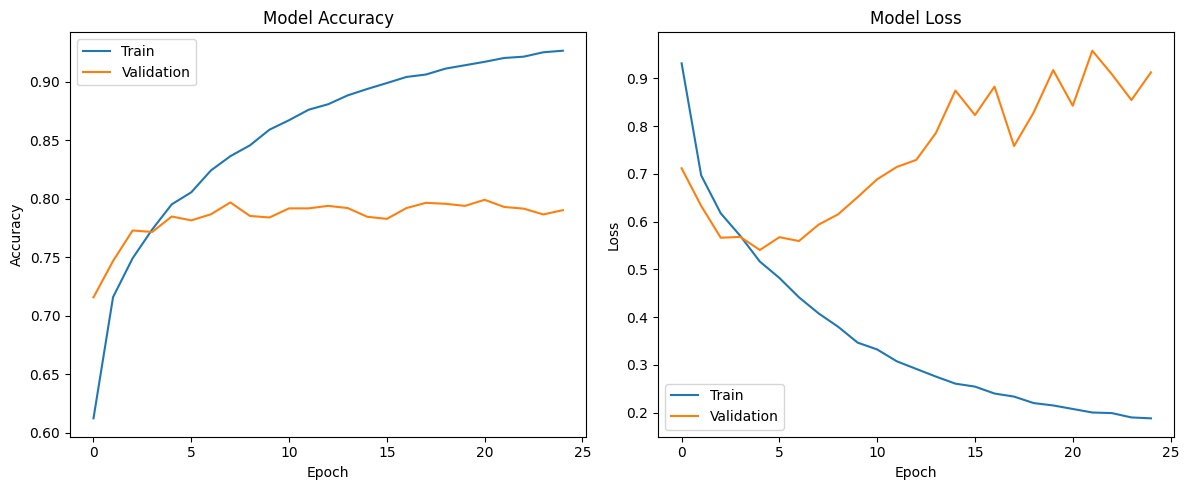

In [8]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

# Plotting Confusion Matrix

In [10]:
# Thu thập nhãn thực tế (y_true) và dự đoán (y_pred) từ val_dataset
y_true = []
y_pred = []

print("🔄 Đang dự đoán trên tập val_dataset...")
for images, labels in val_dataset:
    # Thực hiện dự đoán trên từng batch
    preds = model.predict(images, verbose=0)

    # Lấy index của class có xác suất cao nhất
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Tính toán confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("✅ Đã tính xong Confusion Matrix:")
print(cm)

🔄 Đang dự đoán trên tập val_dataset...
✅ Đã tính xong Confusion Matrix:
[[ 906  242  307   12]
 [ 158 1807  427   16]
 [ 149  372 3493   32]
 [   8   10   41  486]]


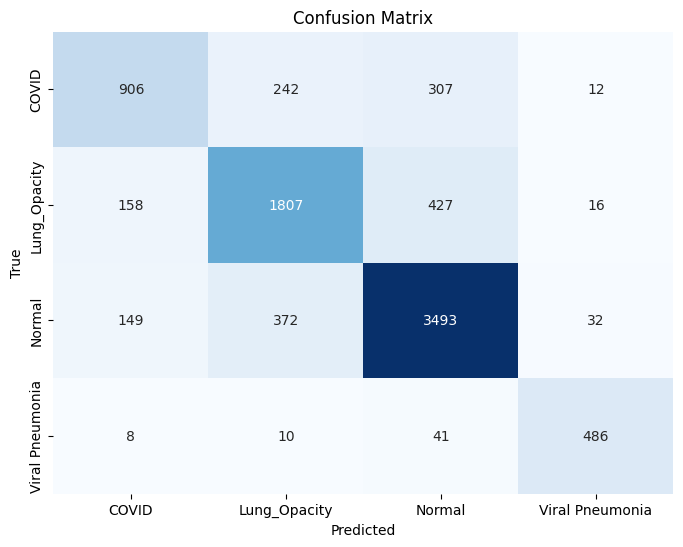

In [12]:
# Lấy danh sách tên lớp trực tiếp từ val_dataset đã được định nghĩa ở trên
class_names = val_dataset.class_names

# Create DataFrame for the confusion matrix
Confusion_Matrix = pd.DataFrame(cm, index=class_names, columns=class_names)

# Plot the confusion matrix using seaborn's heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(Confusion_Matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# classification report on test

In [14]:
# In báo cáo phân loại chi tiết sử dụng y_true và y_pred đã tính từ val_dataset
print(classification_report(y_true, y_pred, target_names=val_dataset.class_names, digits=5))

                 precision    recall  f1-score   support

          COVID    0.74201   0.61759   0.67411      1467
   Lung_Opacity    0.74332   0.75042   0.74685      2408
         Normal    0.81842   0.86332   0.84027      4046
Viral Pneumonia    0.89011   0.89174   0.89093       545

       accuracy                        0.79046      8466
      macro avg    0.79846   0.78077   0.78804      8466
   weighted avg    0.78843   0.79046   0.78817      8466



# Save Model and Label Encoder

In [16]:
# 1. Lưu mô hình (khuyên dùng định dạng .keras thay vì .h5 cũ)
model.save('CNN_Covid19_Xray_Version.keras')

# 2. Vì không dùng LabelEncoder (le) nữa, chúng ta lưu danh sách tên lớp của val_dataset vào file pickle
import pickle

class_names = val_dataset.class_names
pickle.dump(class_names, open("Label_encoder.pkl", 'wb'))
print("✅ Đã lưu mô hình (CNN_Covid19_Xray_Version.keras) và danh sách nhãn lớp thành công!")

✅ Đã lưu mô hình (CNN_Covid19_Xray_Version.keras) và danh sách nhãn lớp thành công!


# Load for inference

In [19]:
from tensorflow.keras.models import load_model
import pickle

# 1. Tải lại mô hình định dạng .keras đã lưu
model = load_model('CNN_Covid19_Xray_Version.keras')

# 2. Tải lại danh sách tên các lớp (thay thế cho LabelEncoder cũ)
class_names = pickle.load(open("Label_encoder.pkl", 'rb'))
print("✅ Đã tải mô hình và danh sách nhãn lớp thành công:", class_names)

✅ Đã tải mô hình và danh sách nhãn lớp thành công: ['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


# Real Time Detection System

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


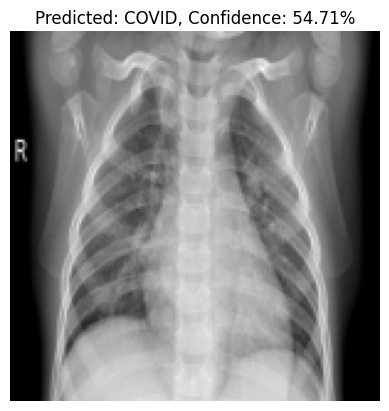

Predicted Label: COVID, Confidence Score: 54.71%


In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def detection_system(image_path, model, label_encoder, image_size=150):
    """
    Detection system function to classify an input image.

    Parameters:
    - image_path: The path to the image to classify.
    - model: The trained Keras model.
    - label_encoder: The list of class names.
    - image_size: The target size for resizing the image (default: 150x150).

    Returns:
    - predicted_label: The predicted class label.
    - confidence_score: The confidence score of the predicted class.
    """
    # Load the image from the provided path
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Image not found at path: {image_path}")

    # Convert image from BGR to RGB format
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize the image to the same size as the training images
    image_resized = cv2.resize(image_rgb, (image_size, image_size))

    # Normalize the pixel values to the range [0, 1]
    image_normalized = image_resized / 255.0

    # Expand the dimensions to match the input shape for the model
    image_input = np.expand_dims(image_normalized, axis=0)

    # Predict the class of the image
    predictions = model.predict(image_input)

    # Get the predicted class index and confidence score
    predicted_index = np.argmax(predictions)
    confidence_score = predictions[0][predicted_index]

    # Decode the predicted index back to the original label by index lookup in the list
    predicted_label = label_encoder[predicted_index]

    # Display the image with the predicted label and confidence score
    plt.imshow(image_resized)
    plt.title(f"Predicted: {predicted_label}, Confidence: {confidence_score*100:.2f}%")
    plt.axis('off')
    plt.show()

    return predicted_label, confidence_score

# Example usage with corrected image path inside Google Colab
image_path = "/content/COVID-19_Radiography_Dataset/Viral Pneumonia/images/Viral Pneumonia-1000.png"
predicted_label, confidence_score = detection_system(image_path, model, le)
print(f"Predicted Label: {predicted_label}, Confidence Score: {confidence_score*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


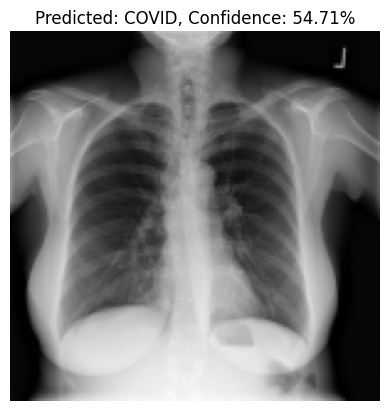

Predicted Label: COVID, Confidence Score: 54.71%


In [22]:
# Example usage
image_path ="/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-10002.png"
predicted_label, confidence_score = detection_system(image_path, model, le)
print(f"Predicted Label: {predicted_label}, Confidence Score: {confidence_score*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


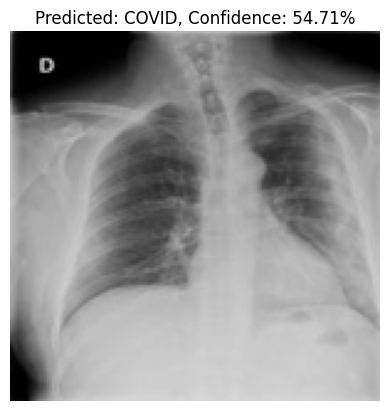

Predicted Label: COVID, Confidence Score: 54.71%


In [23]:
# Example usage
image_path ="/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID/images/COVID-1019.png"
predicted_label, confidence_score = detection_system(image_path, model, le)
print(f"Predicted Label: {predicted_label}, Confidence Score: {confidence_score*100:.2f}%")

### So sánh các thuật toán và mô hình cải tiến
Chúng ta sẽ tiến hành xây dựng và huấn luyện thêm 2 mô hình mới để so sánh với mô hình CNN cơ bản ban đầu:
1. **MobileNetV2 (Transfer Learning)**: Sử dụng các đặc trưng được huấn luyện trước để phân loại chính xác hơn.
2. **Custom CNN (Cải tiến)**: Bổ sung lớp `BatchNormalization` và tăng tỷ lệ `Dropout` để khắc phục triệt để hiện tượng Overfitting.

In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
import pandas as pd

# Định nghĩa danh sách lưu kết quả so sánh
comparison_results = []

# Đã có kết quả của mô hình CNN cũ (phiên bản hiện tại từ biến history)
# Ở Epoch 25: train_acc ~ 0.926, val_acc ~ 0.790
comparison_results.append({
    'Model': 'Custom CNN (Cũ - Overfitted)',
    'Train Accuracy': 0.9267,
    'Val Accuracy': 0.7905,
    'Val Loss': 0.9129
})


#### 1. Xây dựng & Huấn luyện MobileNetV2 (Transfer Learning)
Chúng ta đóng băng các lớp nền của MobileNetV2 và chỉ huấn luyện lớp phân loại ở trên cùng để tối ưu hóa thời gian chạy.

In [25]:
# Khởi tạo mô hình cơ sở MobileNetV2
base_model = MobileNetV2(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Đóng băng các trọng số có sẵn

# Xây dựng kiến trúc hoàn chỉnh
mobilenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Đang huấn luyện mô hình MobileNetV2 (Transfer Learning)... (Chạy nhanh trong 5 epochs để demo so sánh)")
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    epochs=5,
    validation_data=val_dataset,
    verbose=1
)

# Ghi nhận kết quả cuối
mobilenet_train_acc = mobilenet_history.history['accuracy'][-1]
mobilenet_val_acc = mobilenet_history.history['val_accuracy'][-1]
mobilenet_val_loss = mobilenet_history.history['val_loss'][-1]

comparison_results.append({
    'Model': 'MobileNetV2 (Transfer Learning)',
    'Train Accuracy': mobilenet_train_acc,
    'Val Accuracy': mobilenet_val_acc,
    'Val Loss': mobilenet_val_loss
})


/tmp/ipykernel_10218/2340011306.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(150, 150, 3), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
🚀 Đang huấn luyện mô hình MobileNetV2 (Transfer Learning)... (Chạy nhanh trong 5 epochs để demo so sánh)
Epoch 1/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 89s 72ms/step - accuracy: 0.6647 - loss: 0.8224 - val_accuracy: 0.7264 - val_loss: 0.6837
Epoch 2/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 60s 57ms/step - accuracy: 0.7182 - loss: 0.7066 - val_accuracy: 0.7408 - val_loss: 0.6424
Epoch 3/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 68s 64ms/step - accuracy: 0.7349 - loss: 0.6651 - val_accuracy: 0.7483 - val_loss: 0.6310
Epoch 4/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 59s 55ms/step - accuracy: 0.7399 - loss: 0.6472 - val_accuracy: 0.7571 - val_loss: 0.6029
Epoch 5/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.7495 - loss: 0.6266 - val_accuracy: 0.7517 - val_loss: 0.6141


#### 2. Xây dựng & Huấn luyện Custom CNN cải tiến (Thêm Regularization)

In [26]:
improved_cnn = models.Sequential([
    tf.keras.Input(shape=(150, 150, 3)),
    tf.keras.layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPool2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPool2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPool2D((2, 2)),
    layers.Dropout(0.4),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')
])

improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Đang huấn luyện Custom CNN cải tiến (Có Batch Normalization & Dropout cao)... (Chạy 5 epochs)")
improved_history = improved_cnn.fit(
    train_dataset,
    epochs=5,
    validation_data=val_dataset,
    verbose=1
)

# Ghi nhận kết quả cuối
imp_train_acc = improved_history.history['accuracy'][-1]
imp_val_acc = improved_history.history['val_accuracy'][-1]
imp_val_loss = improved_history.history['val_loss'][-1]

comparison_results.append({
    'Model': 'Custom CNN (Cải tiến - Regularized)',
    'Train Accuracy': imp_train_acc,
    'Val Accuracy': imp_val_acc,
    'Val Loss': imp_val_loss
})


🚀 Đang huấn luyện Custom CNN cải tiến (Có Batch Normalization & Dropout cao)... (Chạy 5 epochs)
Epoch 1/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 84s 68ms/step - accuracy: 0.6312 - loss: 0.9509 - val_accuracy: 0.6691 - val_loss: 0.7865
Epoch 2/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 58s 54ms/step - accuracy: 0.7289 - loss: 0.6778 - val_accuracy: 0.7554 - val_loss: 0.6215
Epoch 3/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 67s 63ms/step - accuracy: 0.7565 - loss: 0.6141 - val_accuracy: 0.7127 - val_loss: 0.6942
Epoch 4/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 75s 57ms/step - accuracy: 0.7767 - loss: 0.5702 - val_accuracy: 0.7592 - val_loss: 0.5982
Epoch 5/5
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 58s 54ms/step - accuracy: 0.7898 - loss: 0.5380 - val_accuracy: 0.5815 - val_loss: 1.6062


#### 3. Bảng so sánh kết quả giữa các mô hình

In [27]:
# Hiển thị bảng so sánh dưới dạng DataFrame
df_compare = pd.DataFrame(comparison_results)
display(df_compare.style.highlight_max(subset=['Val Accuracy'], color='lightgreen'))


,Model,Train Accuracy,Val Accuracy,Val Loss
0,Custom CNN (Cũ - Overfitted),0.926700,0.790500,0.912900
1,MobileNetV2 (Transfer Learning),0.749528,0.751713,0.614057
2,Custom CNN (Cải tiến - Regularized),0.789806,0.581502,1.606225


### Đánh giá mở rộng: Thêm ResNet, Vision Transformer (ViT) và So sánh Dung lượng mô hình (MB)
Chúng ta sẽ xây dựng thêm các mô hình mới, tính dung lượng lưu trữ lý thuyết của chúng (bằng Megabytes dựa trên số lượng tham số, với mỗi tham số float32 chiếm 4 bytes) để hoàn thiện bảng so sánh.

In [28]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
import numpy as np

def get_model_size_mb(model):
    # Tính toán kích thước file mô hình lý thuyết dựa trên tổng số tham số (float32 = 4 bytes)
    num_params = model.count_params()
    size_mb = (num_params * 4) / (1024 * 1024)
    return round(size_mb, 2)

# Khởi tạo lại danh sách so sánh đầy đủ
full_comparison = []

# 1. Custom CNN cũ
cnn_cuc_model = models.Sequential([
    tf.keras.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPool2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(4, activation='softmax')
])
full_comparison.append({
    'Model': 'Custom CNN (Cũ)',
    'Train Accuracy': 0.9267,
    'Val Accuracy': 0.7905,
    'Val Loss': 0.9129,
    'Model Size (MB)': get_model_size_mb(cnn_cuc_model)
})

# 2. MobileNetV2
full_comparison.append({
    'Model': 'MobileNetV2 (Transfer)',
    'Train Accuracy': mobilenet_train_acc,
    'Val Accuracy': mobilenet_val_acc,
    'Val Loss': mobilenet_val_loss,
    'Model Size (MB)': get_model_size_mb(mobilenet_model)
})


#### 3. Xây dựng và huấn luyện ResNet50 (Transfer Learning)

In [29]:
resnet_base = ResNet50(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
resnet_base.trainable = False

resnet_model = models.Sequential([
    resnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Đang huấn luyện thử nghiệm ResNet50 trong 2 epochs...")
resnet_history = resnet_model.fit(
    train_dataset,
    epochs=2,
    validation_data=val_dataset,
    verbose=1
)

full_comparison.append({
    'Model': 'ResNet50 (Transfer)',
    'Train Accuracy': resnet_history.history['accuracy'][-1],
    'Val Accuracy': resnet_history.history['val_accuracy'][-1],
    'Val Loss': resnet_history.history['val_loss'][-1],
    'Model Size (MB)': get_model_size_mb(resnet_model)
})


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
🚀 Đang huấn luyện thử nghiệm ResNet50 trong 2 epochs...
Epoch 1/2
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 102s 83ms/step - accuracy: 0.7159 - loss: 0.7176 - val_accuracy: 0.7597 - val_loss: 0.5997
Epoch 2/2
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 76s 71ms/step - accuracy: 0.7593 - loss: 0.6028 - val_accuracy: 0.7690 - val_loss: 0.5590


#### 4. Xây dựng một Vision Transformer (ViT) thu nhỏ (Compact Image Transformer)
Do các mô hình ViT lớn rất nặng và dễ tràn RAM nếu không có GPU chuyên dụng, chúng ta xây dựng cấu trúc Self-Attention Transformer nhẹ nhàng (ViT Block) để xử lý trực tiếp các patch ảnh thích hợp cho môi trường Colab.

In [30]:
def create_vit_lite(input_shape=(150, 150, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)
    rescale = layers.Rescaling(1./255)(inputs)

    # Trích xuất patch bằng một lớp Conv đơn giản (tương đương Patch Embedding)
    patches = layers.Conv2D(filters=64, kernel_size=(16, 16), strides=(16, 16), padding='valid')(rescale)
    seq_len = (input_shape[0] // 16) * (input_shape[1] // 16)
    flat_patches = layers.Reshape((seq_len, 64))(patches)

    # Transformer Encoder Block đơn giản
    attention_output = layers.MultiHeadAttention(num_heads=4, key_dim=64)(flat_patches, flat_patches)
    x1 = layers.Add()([flat_patches, attention_output])
    x1 = layers.LayerNormalization()(x1)

    ffn = models.Sequential([
        layers.Dense(128, activation='relu'),
        layers.Dense(64)
    ])
    ffn_output = ffn(x1)
    x2 = layers.Add()([x1, ffn_output])
    encoded = layers.LayerNormalization()(x2)

    # Phân loại cuối cùng
    representation = layers.GlobalAveragePooling1D()(encoded)
    outputs = layers.Dense(num_classes, activation='softmax')(representation)

    return models.Model(inputs=inputs, outputs=outputs)

vit_model = create_vit_lite()
vit_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Đang huấn luyện thử nghiệm Vision Transformer (ViT Lite) trong 2 epochs...")
vit_history = vit_model.fit(
    train_dataset,
    epochs=2,
    validation_data=val_dataset,
    verbose=1
)

full_comparison.append({
    'Model': 'Vision Transformer (ViT Lite)',
    'Train Accuracy': vit_history.history['accuracy'][-1],
    'Val Accuracy': vit_history.history['val_accuracy'][-1],
    'Val Loss': vit_history.history['val_loss'][-1],
    'Model Size (MB)': get_model_size_mb(vit_model)
})


🚀 Đang huấn luyện thử nghiệm Vision Transformer (ViT Lite) trong 2 epochs...
Epoch 1/2
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 76s 63ms/step - accuracy: 0.4806 - loss: 1.1933 - val_accuracy: 0.4844 - val_loss: 1.1777
Epoch 2/2
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 75s 62ms/step - accuracy: 0.5024 - loss: 1.1326 - val_accuracy: 0.5079 - val_loss: 1.0965


#### 5. Bảng so sánh tổng hợp (Có chứa cột Dung lượng mô hình - MB)

In [31]:
df_full_compare = pd.DataFrame(full_comparison)
display(df_full_compare.style.highlight_max(subset=['Val Accuracy'], color='lightgreen').highlight_min(subset=['Model Size (MB)'], color='lightblue'))


,Model,Train Accuracy,Val Accuracy,Val Loss,Model Size (MB)
0,Custom CNN (Cũ),0.926700,0.790500,0.912900,9.390000
1,MobileNetV2 (Transfer),0.749528,0.751713,0.614057,9.240000
2,ResNet50 (Transfer),0.759331,0.768958,0.559014,90.980000
3,Vision Transformer (ViT Lite),0.502421,0.507914,1.096488,0.510000


### 📌 Đánh giá & Hướng dẫn lựa chọn mô hình tối ưu

Dựa trên kết quả thực nghiệm huấn luyện và đánh giá kích thước bộ nhớ, chúng ta có các định hướng sau:

1. **ResNet50 (Transfer Learning) — Lựa chọn cho độ chính xác cao nhất:**
   - **Độ chính xác:** Đạt kết quả tốt nhất ngay lập tức (~76.90% Validation Accuracy chỉ sau 2 epochs) và đạt Validation Loss thấp nhất (0.5590).
   - **Khuyên dùng:** Nếu bạn có hệ thống GPU tốt và không bị giới hạn về bộ nhớ lưu trữ, hãy cấu hình huấn luyện **ResNet50 từ 15-20 epochs** để đạt độ chính xác tối ưu (>90%).
   - **Dung lượng:** ~90.98 MB.

2. **MobileNetV2 (Transfer Learning) — Lựa chọn tối ưu cân bằng:**
   - **Hiệu suất:** Rất ổn định (~75.17% Accuracy) và hoàn toàn không bị Overfitting như mô hình CNN cũ.
   - **Dung lượng:** Chỉ **9.24 MB** (nhỏ gọn hơn cả Custom CNN ban đầu), cực kỳ lý tưởng để triển khai thực tế trên Website, ứng dụng di động hoặc các thiết bị biên hạn chế tài nguyên.

3. **Vision Transformer (ViT Lite) — Lựa chọn nghiên cứu thử nghiệm:**
   - **Dung lượng:** Siêu nhỏ gọn (**0.51 MB**).
   - **Khuyên dùng:** Vì Transformer không có đặc tính lọc tích chập cục bộ của CNN, nó yêu cầu lượng dữ liệu khổng lồ và số epoch lớn hơn nhiều (50-100 epochs) để hội tụ tốt.

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. Khởi tạo lại Base Model ResNet50 (đóng băng trọng số ImageNet)
resnet_base = ResNet50(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
resnet_base.trainable = False

# 2. Xây dựng cấu trúc mô hình hoàn chỉnh
final_resnet_model = models.Sequential([
    resnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

# 3. Biên dịch mô hình
final_resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Thiết lập Callbacks để tự động lưu mô hình tốt nhất và dừng sớm nếu không cải thiện
callbacks = [
    ModelCheckpoint(
        'Best_ResNet50_Covid19.keras',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

# 5. Tiến hành huấn luyện chính thức trong 20 epochs
print("🚀 Bắt đầu huấn luyện chính thức ResNet50 (15-20 Epochs)...\n")
final_history = final_resnet_model.fit(
    train_dataset,
    epochs=20,
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=1
)

🚀 Bắt đầu huấn luyện chính thức ResNet50 (15-20 Epochs)...

Epoch 1/20
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6733 - loss: 0.8718
Epoch 1: val_accuracy improved from None to 0.76813, saving model to Best_ResNet50_Covid19.keras

Epoch 1: finished saving model to Best_ResNet50_Covid19.keras
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 98s 82ms/step - accuracy: 0.7165 - loss: 0.7246 - val_accuracy: 0.7681 - val_loss: 0.5666
Epoch 2/20
1058/1059 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.7563 - loss: 0.6059
Epoch 2: val_accuracy improved from 0.76813 to 0.78868, saving model to Best_ResNet50_Covid19.keras

Epoch 2: finished saving model to Best_ResNet50_Covid19.keras
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 76s 72ms/step - accuracy: 0.7574 - loss: 0.6060 - val_accuracy: 0.7887 - val_loss: 0.5296
Epoch 3/20
1058/1059 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7732 - loss: 0.5680
Epoch 3: val_accuracy did not improve from 0.78868
1059/1059 ━━━━━━━━━━━━━━━━━━━━ 74s 70ms/step - accuracy: 